# Explaining risk, and testing on an unseen hospital

**Part 1 · Explanations (SHAP).** For any patient-hour, SHAP splits the model's output into how much each feature
pushed the risk **up** or **down**. XGBoost computes exact SHAP values itself (*TreeSHAP*), so no extra library is
needed, here or in the MedTwin backend.

**Part 2 · Unseen hospital.** A model trained at one hospital often works worse at another (different patients,
routines and equipment). The PhysioNet data comes from **two separate hospital systems (A and B)**, so we can measure
that drop directly: train on one, test on the other, and compare with training at home.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score

DATA, MODELS, RESULTS = Path("../data/physionet2019"), Path("../models"), Path("../results")
df = pd.read_parquet(DATA / "risk_features.parquet")
bundle = joblib.load(MODELS / "risk_model.joblib")
model, FEATURES = bundle["model"], bundle["features"]
test = df[df.split == "test"]
print(f"Model: {bundle['name']} · {len(FEATURES)} features · {test.patient.nunique():,} test patients")

Model: XGBoost · 40 features · 8,035 test patients


## Part 1 · What drives the risk, overall

**Mean |SHAP|**: on average, how much each feature moves the risk (in either direction) across test hours.

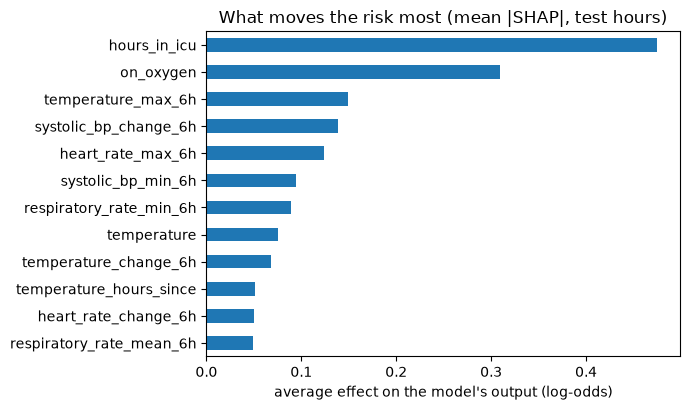

In [2]:
def shap_values(frame):
    """Exact TreeSHAP values from XGBoost: one column per feature, plus the model's starting value (last column)."""
    contributions = model.get_booster().predict(xgb.DMatrix(frame[FEATURES]), pred_contribs=True)
    return pd.DataFrame(contributions[:, :-1], columns=FEATURES, index=frame.index), contributions[:, -1]


sample = test.sample(20_000, random_state=0)
contributions, base = shap_values(sample)
overall = contributions.abs().mean().sort_values().tail(12)
ax = overall.plot.barh(figsize=(7, 4.2), title="What moves the risk most (mean |SHAP|, test hours)")
ax.set_xlabel("average effect on the model's output (log-odds)")
plt.tight_layout()
plt.savefig(RESULTS / "risk_shap_overall.png", dpi=150)
plt.show()

## Part 1 · Explaining one patient

The same idea for a single **high-risk** hour: which signs pushed this patient's risk up, and which pulled it
down. This is what MedTwin's bed panel will show, in words.

Patient A003420, hour 18 in the ICU · model output 0.80 (HIGH)
  ▲ Temperature 6-h max 38.61 °C                  +0.37
  ▲ Temperature 38.61 °C                          +0.32
  ▲ SpO₂ 6-h min 84.5%                            +0.28
  ▼ 18 h in the ICU                               -0.27
  ▲ SpO₂ 6-h mean 89.75%                          +0.19
  ▲ Heart rate rose by 69.5/min over 6 h          +0.15
  ▲ Heart rate 155.5/min                          +0.15
  ▲ Heart rate 6-h max 155.5/min                  +0.12


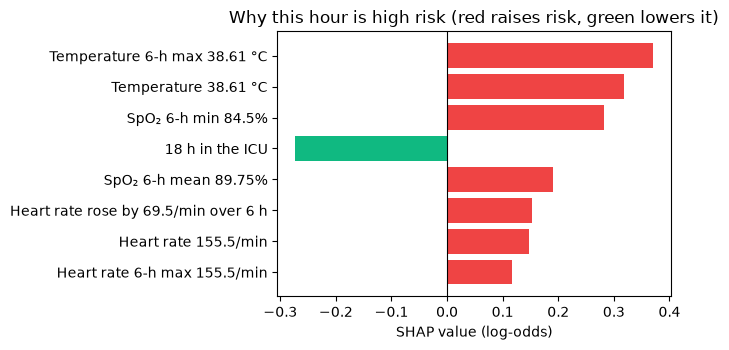

In [3]:
LABELS = {
    "heart_rate": ("Heart rate", "/min"), "spo2": ("SpO₂", "%"), "temperature": ("Temperature", " °C"),
    "systolic_bp": ("Systolic BP", " mmHg"), "diastolic_bp": ("Diastolic BP", " mmHg"),
    "respiratory_rate": ("Breathing rate", "/min"),
}


def describe(feature, value):
    """Turn a feature and its value into plain words, e.g. 'Breathing rate rose by 6/min over 6 h'."""
    if pd.isna(value):
        return f"{feature}: not measured"
    for key, (label, unit) in LABELS.items():
        if feature == key:
            return f"{label} {value:g}{unit}"
        if feature.startswith(key + "_"):
            kind = feature[len(key) + 1:]
            if kind == "change_6h":
                return f"{label} {'rose' if value > 0 else 'fell'} by {abs(value):g}{unit} over 6 h"
            if kind == "hours_since":
                return f"{label} last measured {value:g} h ago"
            return f"{label} 6-h {kind.split('_')[0]} {value:g}{unit}"
    names = {"age": f"Age {value:g}", "hours_in_icu": f"{value:g} h in the ICU",
             "on_oxygen": "On extra oxygen" if value else "Breathing room air", "male": "Male" if value else "Female"}
    return names.get(feature, f"{feature} = {value:g}")


high_hour = sample[model.predict_proba(sample[FEATURES])[:, 1] >= bundle["levels"]["high"]].iloc[0]
row = sample.loc[[high_hour.name]]
contribution = shap_values(row)[0].iloc[0].sort_values(key=abs, ascending=False).head(8)
risk = model.predict_proba(row[FEATURES])[0, 1]

print(f"Patient {high_hour.patient}, hour {int(high_hour.hours_in_icu)} in the ICU · model output {risk:.2f} (HIGH)")
for feature, effect in contribution.items():
    print(f"  {'▲' if effect > 0 else '▼'} {describe(feature, high_hour[feature]):<45} {effect:+.2f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
labels = [describe(feature, high_hour[feature]) for feature in contribution.index][::-1]
ax.barh(labels, contribution.values[::-1], color=["#ef4444" if v > 0 else "#10b981" for v in contribution.values[::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Why this hour is high risk (red raises risk, green lowers it)")
ax.set_xlabel("SHAP value (log-odds)")
plt.tight_layout()
plt.savefig(RESULTS / "risk_shap_one_patient.png", dpi=150)
plt.show()

## Part 2 · How different are the two hospital systems?

Before training anything: the patients and the measuring routines differ, which is why a model may not transfer.

In [4]:
raw = pd.read_parquet(DATA / "all_hours.parquet")
VITALS = {"HR": "heart rate", "O2Sat": "SpO₂", "Temp": "temperature", "SBP": "systolic BP", "DBP": "diastolic BP", "Resp": "breathing rate"}
differences = pd.DataFrame({
    hospital: {
        "patients": part.patient.nunique(),
        "sepsis patients %": round(100 * part.groupby("patient").SepsisLabel.max().mean(), 1),
        "median age": part.groupby("patient").Age.first().median(),
        **{f"{label} missing %": round(100 * part[column].isna().mean(), 1) for column, label in VITALS.items()},
    }
    for hospital, part in raw.groupby("hospital")
})
differences

,A,B
patients,20336.00,20000.0
sepsis patients %,8.80,5.7
median age,64.67,62.0
heart rate missing %,7.70,12.1
SpO₂ missing %,12.00,14.1
temperature missing %,66.20,66.1
systolic BP missing %,15.20,13.9
diastolic BP missing %,48.10,13.9
breathing rate missing %,9.80,21.1


## Part 2 · The experiment

For each hospital system, an XGBoost model (same settings as Day 25) is trained on its own training patients,
with 10% of them as validation patients for early stopping and the alarm level. Each model is then tested on the
**test patients of both** systems. NEWS2 is shown for reference.

In [5]:
def train_on(hospital):
    patients = df.loc[(df.hospital == hospital) & (df.split == "train"), "patient"].unique()
    validation = set(np.random.default_rng(7).choice(patients, size=len(patients) // 10, replace=False))
    part = df[(df.hospital == hospital) & (df.split == "train")]
    fit_part, val_part = part[~part.patient.isin(validation)], part[part.patient.isin(validation)]
    weight = (fit_part.target == 0).sum() / (fit_part.target == 1).sum()
    trained = xgb.XGBClassifier(
        n_estimators=1000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
        min_child_weight=20, scale_pos_weight=weight, eval_metric="aucpr", early_stopping_rounds=50,
        tree_method="hist", n_jobs=-1, random_state=0,
    ).fit(fit_part[FEATURES], fit_part.target, eval_set=[(val_part[FEATURES], val_part.target)], verbose=False)
    # Alarm level: as many alarms as NEWS2 >= 5 at the HOME hospital's validation patients.
    share = (val_part.news2 >= 5).mean()
    threshold = float(np.quantile(trained.predict_proba(val_part[FEATURES])[:, 1], 1 - share))
    return trained, threshold


trained = {hospital: train_on(hospital) for hospital in ("A", "B")}

rows = []
for test_hospital in ("A", "B"):
    part = df[(df.hospital == test_hospital) & (df.split == "test")]
    for train_hospital in ("A", "B"):
        clf, threshold = trained[train_hospital]
        score = clf.predict_proba(part[FEATURES])[:, 1]
        alarms = score >= threshold
        rows.append({"test hospital": test_hospital, "trained on": train_hospital,
                     "setting": "home" if train_hospital == test_hospital else "unseen",
                     "AUROC": roc_auc_score(part.target, score), "AUPRC": average_precision_score(part.target, score),
                     "hours alarmed %": 100 * alarms.mean(), "catches %": 100 * alarms[part.target == 1].mean()})
    news2 = part.news2.values
    rows.append({"test hospital": test_hospital, "trained on": "-", "setting": "NEWS2",
                 "AUROC": roc_auc_score(part.target, news2), "AUPRC": average_precision_score(part.target, news2),
                 "hours alarmed %": 100 * (news2 >= 5).mean(), "catches %": 100 * (news2 >= 5)[part.target == 1].mean()})

experiment = pd.DataFrame(rows)
experiment.to_csv(RESULTS / "risk_unseen_hospital.csv", index=False)
experiment.round({"AUROC": 3, "AUPRC": 3, "hours alarmed %": 1, "catches %": 1})

,test hospital,trained on,setting,AUROC,AUPRC,hours alarmed %,catches %
0,A,A,home,0.777,0.072,31.5,70.9
1,A,B,unseen,0.739,0.056,17.6,49.6
2,A,-,NEWS2,0.627,0.021,29.7,47.3
3,B,A,unseen,0.776,0.034,23.3,61.1
4,B,B,home,0.786,0.057,17.1,54.8
5,B,-,NEWS2,0.687,0.018,18.3,43.3


The drop at an unseen hospital (same test patients, model trained elsewhere vs at home):
  Hospital A: AUROC 0.777 at home -> 0.739 unseen (-4.9%); AUPRC 0.072 -> 0.056 (-21%); NEWS2 AUROC 0.627
     alarms: 31% of hours at home vs 18% unseen (the alarm level chosen elsewhere doesn't give the same alarm load)
  Hospital B: AUROC 0.786 at home -> 0.776 unseen (-1.2%); AUPRC 0.057 -> 0.034 (-40%); NEWS2 AUROC 0.687
     alarms: 17% of hours at home vs 23% unseen (the alarm level chosen elsewhere doesn't give the same alarm load)


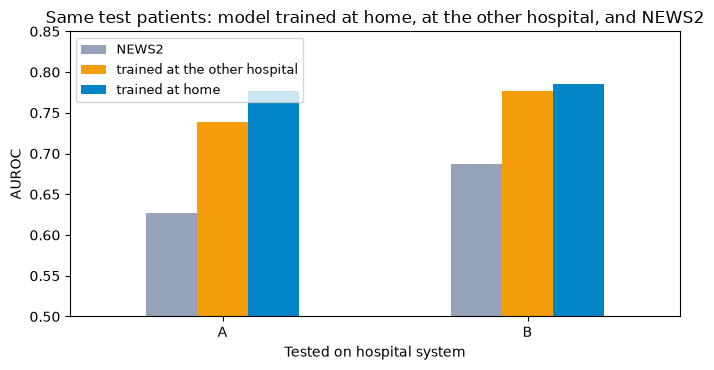

In [6]:
print("The drop at an unseen hospital (same test patients, model trained elsewhere vs at home):")
for test_hospital in ("A", "B"):
    rows = experiment[experiment["test hospital"] == test_hospital].set_index("setting")
    home, unseen, news2 = rows.loc["home"], rows.loc["unseen"], rows.loc["NEWS2"]
    print(f"  Hospital {test_hospital}: AUROC {home.AUROC:.3f} at home -> {unseen.AUROC:.3f} unseen "
          f"({100 * (unseen.AUROC - home.AUROC) / home.AUROC:+.1f}%); AUPRC {home.AUPRC:.3f} -> {unseen.AUPRC:.3f} "
          f"({100 * (unseen.AUPRC - home.AUPRC) / home.AUPRC:+.0f}%); NEWS2 AUROC {news2.AUROC:.3f}")
    print(f"     alarms: {home['hours alarmed %']:.0f}% of hours at home vs {unseen['hours alarmed %']:.0f}% unseen "
          f"(the alarm level chosen elsewhere doesn't give the same alarm load)")

fig, ax = plt.subplots(figsize=(7, 3.8))
plot = experiment.pivot(index="test hospital", columns="setting", values="AUROC")[["NEWS2", "unseen", "home"]]
plot.plot.bar(ax=ax, rot=0, color=["#94a3b8", "#f59e0b", "#0284c7"])
ax.set_ylim(0.5, 0.85)
ax.set_ylabel("AUROC")
ax.set_xlabel("Tested on hospital system")
ax.set_title("Same test patients: model trained at home, at the other hospital, and NEWS2")
ax.legend(["NEWS2", "trained at the other hospital", "trained at home"], loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS / "risk_unseen_hospital.png", dpi=150)
plt.show()

## Notes for the report

* **Explanations:** TreeSHAP values come straight from XGBoost, so every risk score in MedTwin can be shown with its
  top reasons, in words.
* **Unseen-hospital drop:** compare each hospital's *home* and *unseen* rows on the **same** test patients; the gap is
  the cost of moving a model to a hospital it has never seen.
* **Alarm load shifts too:** an alarm level tuned at one hospital gives a different alarm rate at another, so even a
  model that ranks patients well needs re-tuning before use elsewhere.
* **Day 27:** can that drop be reduced? (1) **fine-tuning** with a small share of the new hospital's data, and
  (2) **federated averaging**, where hospitals train together without sharing patient data.